# Projet Biomécanique — Groupe 3
## Étape 1 : Préparation et nettoyage des données

---

### Objectifs

| Étape | Description |
|-------|-------------|
| **1** | Chargement des fichiers `.c3d` et extraction des trajectoires de marqueurs |
| **2** | Calcul des **centres articulaires** par moyenne géométrique (coude, poignet, genou) |
| **3** | **Filtrage passe-bas Butterworth** (fc = 10 Hz) pour éliminer le bruit haute fréquence |

### Données disponibles
- **25 marqueurs** par essai (shape brute : `(N_frames, 3)` par marqueur)
- **Fréquence d'acquisition** : 100 Hz
- **2 conditions** : Lancer Franc (`LF/`) et Tir Extérieur (`Jump_Shot/`)
- **5 essais** par condition

---
## 0. Imports et paramètres globaux

In [1]:
import os
import numpy as np
import ezc3d
from scipy.signal import butter, filtfilt, freqz
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# Style global des figures
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})

# ── Paramètres du filtre ────────────────────────────────────────────────────
CUTOFF_HZ   = 10.0   # Fréquence de coupure (Hz)
FILTER_ORDER = 4     # Ordre du filtre Butterworth

# ── Chemins des données ─────────────────────────────────────────────────────
BASE_DIR = os.getcwd()          # dossier du notebook
DATA_DIRS = {
    "LancerFranc":  os.path.join(BASE_DIR, "LF"),
    "TirExterieur": os.path.join(BASE_DIR, "Jump_Shot"),
}

print("Imports OK")
print(f"Dossier de travail : {BASE_DIR}")
for cond, path in DATA_DIRS.items():
    fichiers = [f for f in os.listdir(path) if f.endswith('.c3d')]
    print(f"  {cond:15s} → {len(fichiers)} fichiers .c3d")

Imports OK
Dossier de travail : c:\Master\M1\S7\ProjetBiomeca\Groupe_3
  LancerFranc     → 5 fichiers .c3d
  TirExterieur    → 5 fichiers .c3d


---
## 1. Chargement des fichiers C3D

Les fichiers `.c3d` stockent les coordonnées 3D des marqueurs en **millimètres**.
On convertit en **mètres** et on masque les frames invalides (résidu < 0) avec `NaN`.

In [2]:
def load_c3d(filepath):
    """
    Charge un fichier C3D et retourne les trajectoires des marqueurs.

    Returns
    -------
    markers : dict  {nom_marqueur: np.ndarray(N, 3)}  en mètres
    freq    : float  fréquence d'échantillonnage (Hz)
    """
    c3d = ezc3d.c3d(filepath)
    freq   = float(c3d["parameters"]["POINT"]["RATE"]["value"][0])
    labels = c3d["parameters"]["POINT"]["LABELS"]["value"]
    data   = c3d["data"]["points"]   # shape : (4, nb_marqueurs, N_frames)

    markers = {}
    for i, label in enumerate(labels):
        traj = data[:3, i, :].T / 1000.0        # (N, 3)  mm → m
        residuals = data[3, i, :]               # résidu : -1 = données manquantes
        traj[residuals < 0, :] = np.nan         # frames invalides → NaN
        markers[label.strip()] = traj

    return markers, freq


# ── Test sur un fichier exemple ─────────────────────────────────────────────
exemple_path = os.path.join(DATA_DIRS["TirExterieur"], "Tirext1.c3d")
markers_ex, freq_ex = load_c3d(exemple_path)

print(f"Fichier chargé : {os.path.basename(exemple_path)}")
print(f"  Fréquence d'échantillonnage : {freq_ex:.0f} Hz")
print(f"  Nombre de marqueurs         : {len(markers_ex)}")
print(f"  Nombre de frames            : {next(iter(markers_ex.values())).shape[0]}")
print(f"\nMarqueurs disponibles :")
print("  " + ", ".join(markers_ex.keys()))

Fichier chargé : Tirext1.c3d
  Fréquence d'échantillonnage : 100 Hz
  Nombre de marqueurs         : 25
  Nombre de frames            : 696

Marqueurs disponibles :
  Nuque, EpauleDroitePost, EpauleGauchePost, EpauleDroiteAnt, EpauleGaucheAnt, EpauleGaucheLat, EpauleDroiteLat, CoudeDroitExt, CoudeDroitInt, HancheDroite, HancheGauche, CoudeGaucheInt, CoudeGaucheExt, PoignetDroitExt, PoignetDroitInt, PoignetGaucheInt, PoignetGaucheExt, GenouDroitExt, MainDroiteDos, MainGaucheDos, DosDroitBas, GenouDroitInt, GenouGaucheInt, GenouGaucheExt, DosGaucheBas


### 1.1 Vérification des données manquantes

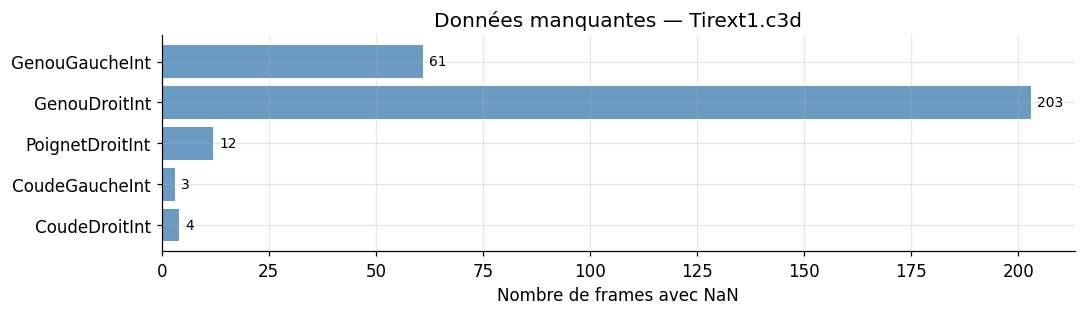

  5 marqueurs affectés sur 25


In [3]:
# Comptage des NaN par marqueur (sur l'axe Y)
nan_counts = {name: int(np.isnan(traj[:, 1]).sum()) for name, traj in markers_ex.items()}
nan_nonzero = {k: v for k, v in nan_counts.items() if v > 0}

if nan_nonzero:
    fig, ax = plt.subplots(figsize=(10, 3))
    names = list(nan_nonzero.keys())
    vals  = list(nan_nonzero.values())
    bars = ax.barh(names, vals, color='steelblue', alpha=0.8)
    ax.bar_label(bars, padding=4, fontsize=9)
    ax.set_xlabel("Nombre de frames avec NaN")
    ax.set_title(f"Données manquantes — {os.path.basename(exemple_path)}")
    plt.tight_layout()
    plt.show()
    print(f"  {len(nan_nonzero)} marqueurs affectés sur {len(markers_ex)}")
else:
    print("  Aucune donnée manquante détectée.")

---
## 2. Calcul des centres articulaires

Pour chaque articulation instrumentée avec deux marqueurs (interne **Int** et externe **Ext**), on estime le centre articulaire comme leur **moyenne géométrique** :

$$\vec{r}_{\text{centre}} = \frac{\vec{r}_{\text{Ext}} + \vec{r}_{\text{Int}}}{2}$$

| Centre calculé | Marqueur Ext | Marqueur Int |
|---------------|-------------|-------------|
| CoudeDroit | CoudeDroitExt | CoudeDroitInt |
| CoudeGauche | CoudeGaucheExt | CoudeGaucheInt |
| PoignetDroit | PoignetDroitExt | PoignetDroitInt |
| PoignetGauche | PoignetGaucheExt | PoignetGaucheInt |
| GenouDroit | GenouDroitExt | GenouDroitInt |
| GenouGauche | GenouGaucheExt | GenouGaucheInt |

In [4]:
def compute_joint_centers(markers):
    """
    Calcule les centres articulaires par moyenne géométrique.
    Modifie le dictionnaire en place et retourne le dictionnaire enrichi.
    """
    joint_pairs = {
        "CoudeDroit":    ("CoudeDroitExt",    "CoudeDroitInt"),
        "CoudeGauche":   ("CoudeGaucheExt",   "CoudeGaucheInt"),
        "PoignetDroit":  ("PoignetDroitExt",  "PoignetDroitInt"),
        "PoignetGauche": ("PoignetGaucheExt", "PoignetGaucheInt"),
        "GenouDroit":    ("GenouDroitExt",     "GenouDroitInt"),
        "GenouGauche":   ("GenouGaucheExt",    "GenouGaucheInt"),
    }

    for center, (ext, int_) in joint_pairs.items():
        if ext in markers and int_ in markers:
            markers[center] = (markers[ext] + markers[int_]) / 2.0
            print(f"  ✓  {center:20s} = ({ext} + {int_}) / 2")
        else:
            missing = [l for l in [ext, int_] if l not in markers]
            print(f"  ✗  {center:20s} — marqueurs manquants : {missing}")

    return markers


# ── Application sur le fichier exemple ─────────────────────────────────────
print("Centres articulaires calculés :")
markers_ex = compute_joint_centers(markers_ex)
print(f"\n  Marqueurs totaux après calcul : {len(markers_ex)}  "
      f"({len(markers_ex) - 25} nouveaux centres)")

Centres articulaires calculés :
  ✓  CoudeDroit           = (CoudeDroitExt + CoudeDroitInt) / 2
  ✓  CoudeGauche          = (CoudeGaucheExt + CoudeGaucheInt) / 2
  ✓  PoignetDroit         = (PoignetDroitExt + PoignetDroitInt) / 2
  ✓  PoignetGauche        = (PoignetGaucheExt + PoignetGaucheInt) / 2
  ✓  GenouDroit           = (GenouDroitExt + GenouDroitInt) / 2
  ✓  GenouGauche          = (GenouGaucheExt + GenouGaucheInt) / 2

  Marqueurs totaux après calcul : 31  (6 nouveaux centres)


### 2.1 Visualisation : position des marqueurs ext/int et du centre calculé

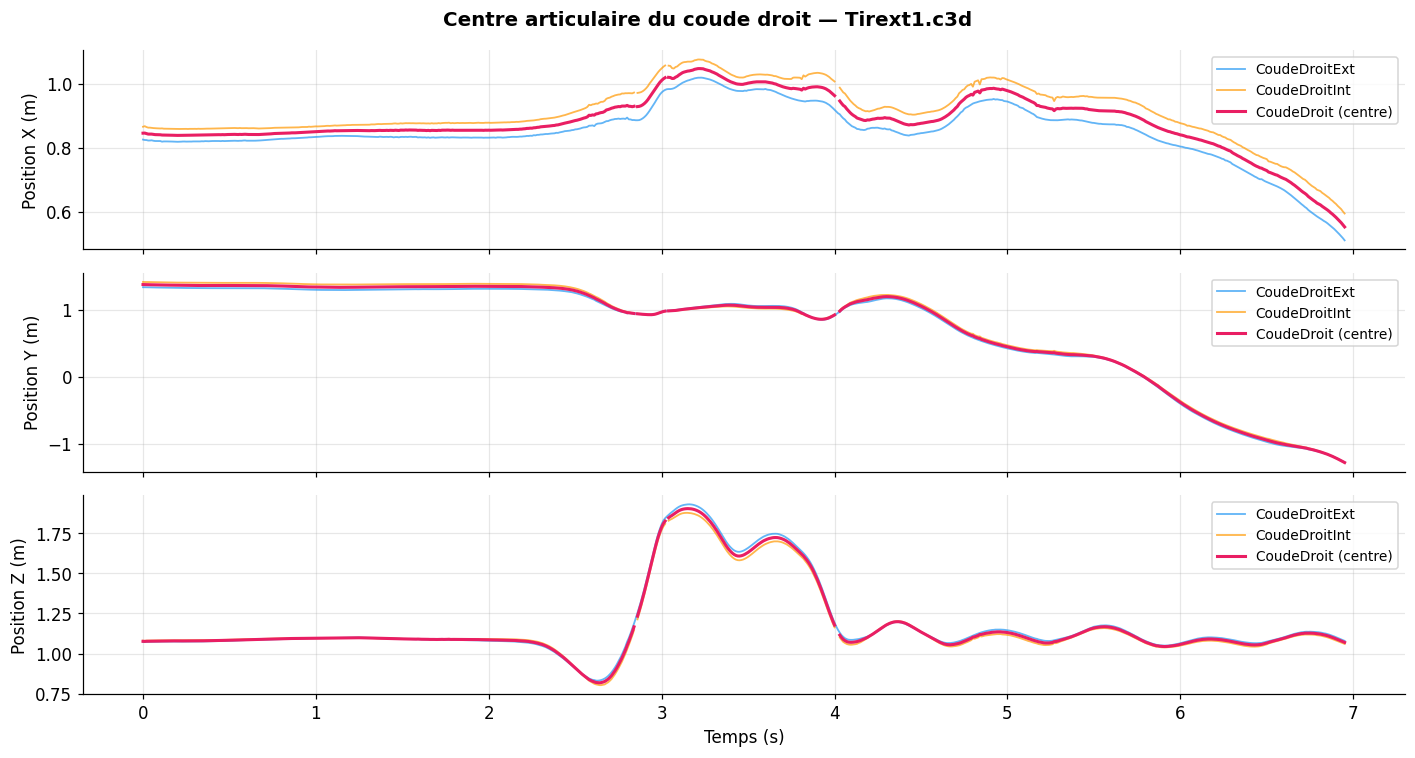

In [5]:
# Comparaison CoudeDroitExt / CoudeDroitInt / CoudeDroit (centre)
t = np.arange(next(iter(markers_ex.values())).shape[0]) / freq_ex

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
fig.suptitle("Centre articulaire du coude droit — Tirext1.c3d", fontsize=13, fontweight='bold')

for ax, axis_idx, axis_name in zip(axes, [0, 1, 2], ['X', 'Y', 'Z']):
    ax.plot(t, markers_ex['CoudeDroitExt'][:, axis_idx],
            color='#2196F3', lw=1.2, alpha=0.7, label='CoudeDroitExt')
    ax.plot(t, markers_ex['CoudeDroitInt'][:, axis_idx],
            color='#FF9800', lw=1.2, alpha=0.7, label='CoudeDroitInt')
    ax.plot(t, markers_ex['CoudeDroit'][:, axis_idx],
            color='#E91E63', lw=2.0, label='CoudeDroit (centre)')
    ax.set_ylabel(f"Position {axis_name} (m)")
    ax.legend(loc='upper right', fontsize=9)

axes[-1].set_xlabel("Temps (s)")
plt.tight_layout()
plt.show()

---
## 3. Filtrage passe-bas de Butterworth

Le filtrage est indispensable avant toute **dérivation numérique** (vitesse, accélération).  
Sans filtrage, le bruit est amplifié exponentiellement à chaque dérivation.

**Choix du filtre :**
- Type : **Butterworth** (réponse en fréquence maximalement plate)
- Ordre : **4** (atténuation de −80 dB/décade au-delà de fc)
- Fréquence de coupure : **fc = 10 Hz** (le mouvement humain est < 5–8 Hz ; le bruit dépasse 20 Hz)
- Application : **`filtfilt`** (zéro déphasage — filtre aller-retour)

Les lacunes (`NaN`) sont **interpolées linéairement** avant filtrage, puis **restaurées** après.
> **Limite des données :** aucun marqueur de cheville n'est disponible dans les fichiers fournis. L'angle du genou est donc estimé avec une direction verticale comme référence pour le segment jambier ; il ne s'agit pas d'un angle anatomique complet hanche-genou-cheville.


In [6]:
def butterworth_lowpass(data, cutoff=CUTOFF_HZ, fs=100.0, order=FILTER_ORDER):
    """
    Filtre passe-bas Butterworth zero-phase (filtfilt) sur un array (N, 3).
    Les NaN sont interpolés avant filtrage et restaurés après.
    """
    nyquist = fs / 2.0
    b, a = butter(order, cutoff / nyquist, btype='low', analog=False)
    filtered = np.full_like(data, np.nan)

    for axis in range(data.shape[1]):   # X, Y, Z indépendamment
        col  = data[:, axis].copy()
        nans = np.isnan(col)
        if nans.all():
            continue
        if nans.any():
            idx = np.arange(len(col))
            col = np.interp(idx, idx[~nans], col[~nans])   # interpolation linéaire
        filtered[:, axis] = filtfilt(b, a, col)
        filtered[nans, axis] = np.nan                       # on restaure les NaN

    return filtered


def filter_all_markers(markers, cutoff=CUTOFF_HZ, fs=100.0, order=FILTER_ORDER):
    """Applique le filtre Butterworth sur l'ensemble des trajectoires."""
    markers_filt = {}
    for name, traj in markers.items():
        markers_filt[name] = butterworth_lowpass(traj, cutoff, fs, order)
    print(f"  Filtrage appliqué sur {len(markers_filt)} trajectoires  "
          f"(fc = {cutoff} Hz, ordre = {order})")
    return markers_filt


# ── Application sur le fichier exemple ─────────────────────────────────────
markers_ex_filt = filter_all_markers(markers_ex, fs=freq_ex)
print("  Filtrage terminé.")

  Filtrage appliqué sur 31 trajectoires  (fc = 10.0 Hz, ordre = 4)
  Filtrage terminé.


### 3.1 Réponse en fréquence du filtre

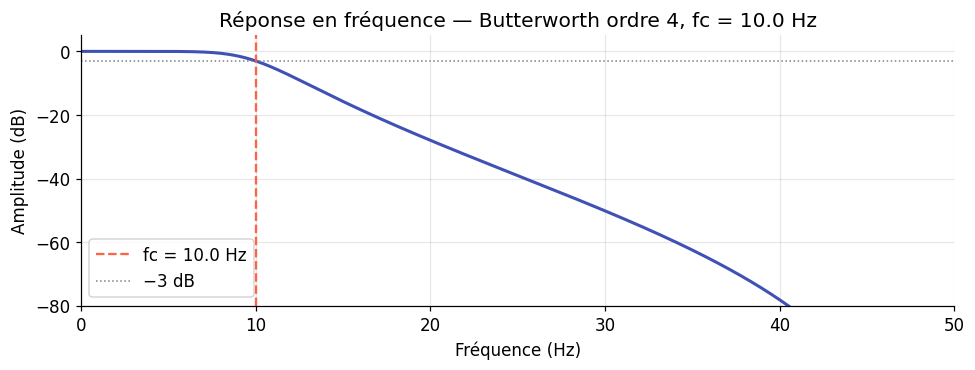

In [7]:
b, a = butter(FILTER_ORDER, CUTOFF_HZ / (freq_ex / 2), btype='low')
w, h = freqz(b, a, worN=1024, fs=freq_ex)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(w, 20 * np.log10(np.abs(h)), color='#3F51B5', lw=2)
ax.axvline(CUTOFF_HZ, color='tomato', linestyle='--', lw=1.5,
           label=f'fc = {CUTOFF_HZ} Hz')
ax.axhline(-3, color='grey', linestyle=':', lw=1, label='−3 dB')
ax.set_xlim(0, freq_ex / 2)
ax.set_ylim(-80, 5)
ax.set_xlabel('Fréquence (Hz)')
ax.set_ylabel('Amplitude (dB)')
ax.set_title(f'Réponse en fréquence — Butterworth ordre {FILTER_ORDER}, fc = {CUTOFF_HZ} Hz')
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Comparaison signal brut vs filtré — Position et Vitesse

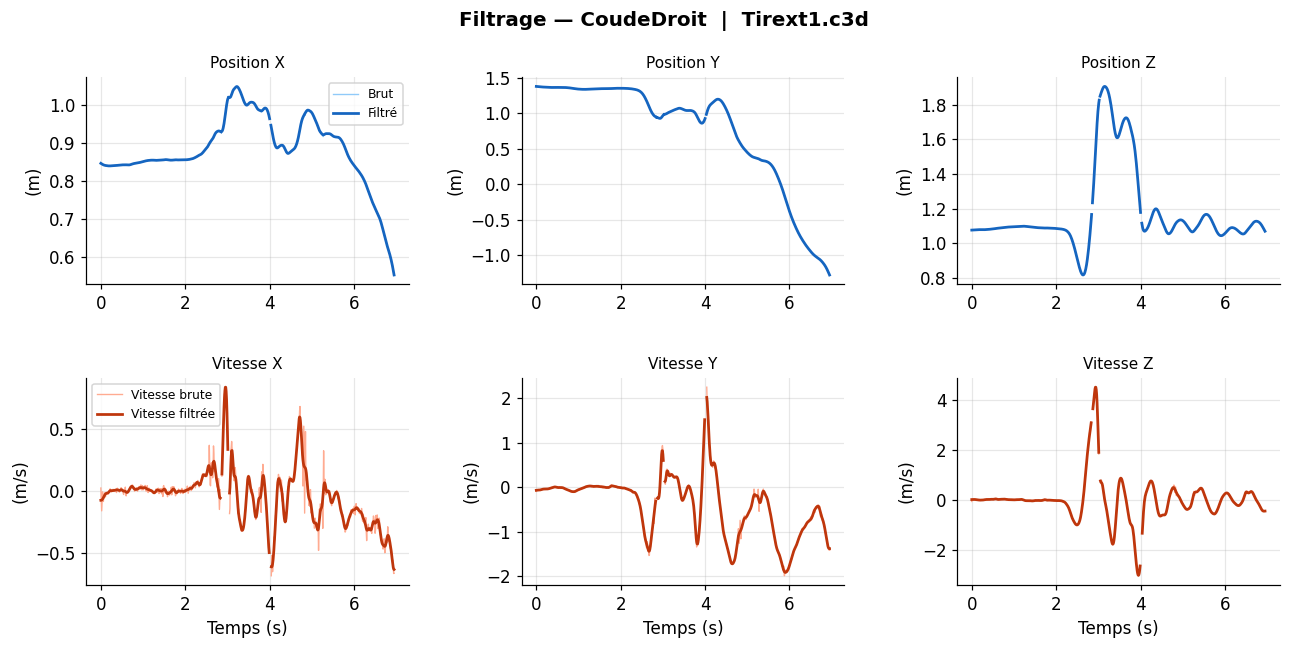

In [8]:
def plot_brut_vs_filtre(markers_raw, markers_filt, freq,
                        marker_name='CoudeDroit', axes_idx=(0, 1, 2), titre=''):
    """
    Affiche position et vitesse (brut vs filtré) pour un marqueur donné.
    """
    if marker_name not in markers_raw:
        print(f"Marqueur '{marker_name}' introuvable.")
        return

    axis_labels = ['X', 'Y', 'Z']
    dt = 1.0 / freq
    t  = np.arange(markers_raw[marker_name].shape[0]) * dt

    fig = plt.figure(figsize=(14, 6))
    fig.suptitle(f'Filtrage — {marker_name}  |  {titre}',
                 fontsize=13, fontweight='bold')

    n_axes = len(axes_idx)
    gs = gridspec.GridSpec(2, n_axes, figure=fig, hspace=0.45, wspace=0.35)

    for col, ax_idx in enumerate(axes_idx):
        raw  = markers_raw[marker_name][:, ax_idx]
        filt = markers_filt[marker_name][:, ax_idx]

        # Position
        ax_pos = fig.add_subplot(gs[0, col])
        ax_pos.plot(t, raw,  color='#90CAF9', lw=0.9, label='Brut')
        ax_pos.plot(t, filt, color='#1565C0', lw=1.8, label='Filtré')
        ax_pos.set_title(f'Position {axis_labels[ax_idx]}', fontsize=10)
        ax_pos.set_ylabel('(m)')
        if col == 0:
            ax_pos.legend(fontsize=8)

        # Vitesse
        ax_vel = fig.add_subplot(gs[1, col])
        vel_raw  = np.gradient(raw,  dt)
        vel_filt = np.gradient(filt, dt)
        ax_vel.plot(t, vel_raw,  color='#FFAB91', lw=0.9, label='Vitesse brute')
        ax_vel.plot(t, vel_filt, color='#BF360C', lw=1.8, label='Vitesse filtrée')
        ax_vel.set_title(f'Vitesse {axis_labels[ax_idx]}', fontsize=10)
        ax_vel.set_ylabel('(m/s)')
        ax_vel.set_xlabel('Temps (s)')
        if col == 0:
            ax_vel.legend(fontsize=8)

    plt.show()


# ── Visualisation sur le fichier exemple ───────────────────────────────────
plot_brut_vs_filtre(
    markers_ex, markers_ex_filt, freq_ex,
    marker_name='CoudeDroit',
    axes_idx=(0, 1, 2),
    titre='Tirext1.c3d'
)

---
## 4. Pipeline complet — Tous les essais

On applique les 3 étapes sur **l'ensemble des 10 fichiers** (5 LF + 5 Jump Shot).

In [9]:
def preparer_fichier(filepath):
    """
    Pipeline complet pour un fichier C3D :
    1. Chargement  2. Centres articulaires  3. Filtrage Butterworth

    Returns
    -------
    markers_raw  : dict — données brutes + centres articulaires
    markers_filt : dict — données filtrées
    freq         : float — fréquence d'échantillonnage
    """
    markers_raw, freq = load_c3d(filepath)
    markers_raw  = compute_joint_centers(markers_raw)
    markers_filt = filter_all_markers(markers_raw, fs=freq)
    return markers_raw, markers_filt, freq


def preparer_tous_les_essais(data_dirs=DATA_DIRS):
    """
    Traite tous les fichiers C3D de chaque condition.

    Returns
    -------
    resultats : dict
        { condition: { nom_fichier: {'raw': ..., 'filt': ..., 'freq': ...} } }
    """
    resultats = {}
    for condition, folder in data_dirs.items():
        resultats[condition] = {}
        fichiers = sorted(f for f in os.listdir(folder) if f.endswith('.c3d'))
        print(f"\n{'━'*55}")
        print(f"  Condition : {condition}  ({len(fichiers)} essais)")
        print(f"{'━'*55}")
        for fname in fichiers:
            fpath = os.path.join(folder, fname)
            print(f"\n  ▶  {fname}")
            raw, filt, freq = preparer_fichier(fpath)
            n_frames = next(iter(raw.values())).shape[0]
            nan_total = sum(np.isnan(v).sum() for v in raw.values())
            print(f"     {n_frames} frames | {len(raw)} marqueurs | {nan_total} NaN bruts")
            resultats[condition][fname] = {'raw': raw, 'filt': filt, 'freq': freq}
    return resultats


resultats = preparer_tous_les_essais()
print("\n\n  ✅  Traitement de tous les essais terminé.")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Condition : LancerFranc  (5 essais)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  ▶  Lancer1.c3d
  ✓  CoudeDroit           = (CoudeDroitExt + CoudeDroitInt) / 2
  ✓  CoudeGauche          = (CoudeGaucheExt + CoudeGaucheInt) / 2
  ✓  PoignetDroit         = (PoignetDroitExt + PoignetDroitInt) / 2
  ✓  PoignetGauche        = (PoignetGaucheExt + PoignetGaucheInt) / 2
  ✓  GenouDroit           = (GenouDroitExt + GenouDroitInt) / 2
  ✓  GenouGauche          = (GenouGaucheExt + GenouGaucheInt) / 2
  Filtrage appliqué sur 31 trajectoires  (fc = 10.0 Hz, ordre = 4)
     500 frames | 31 marqueurs | 1863 NaN bruts

  ▶  Lancer2.c3d
  ✓  CoudeDroit           = (CoudeDroitExt + CoudeDroitInt) / 2
  ✓  CoudeGauche          = (CoudeGaucheExt + CoudeGaucheInt) / 2
  ✓  PoignetDroit         = (PoignetDroitExt + PoignetDroitInt) / 2
  ✓  PoignetGauche        = (PoignetGaucheExt + PoignetGaucheInt) / 2
  ✓  GenouDroit           = (Gen

---
## 4. Normalisation temporelle et comparaison

La dur?e du jump shot peut ?tre diff?rente de celle du lancer franc. Le temps brut ne permet donc pas de superposer directement les courbes. Seule la phase propulsive est conserv?e : elle va du point le plus bas du bassin (**Dip**) jusqu'? la lib?ration estim?e.

Chaque signal est ensuite interpol? avec `np.interp` sur 101 points r?guli?rement r?partis entre 0 et 100 %. Les essais peuvent ainsi ?tre compar?s sur une m?me ?chelle temporelle.


In [ ]:
N_POINTS_NORMALISES = 101
POURCENTAGE_PHASE = np.linspace(0.0, 100.0, N_POINTS_NORMALISES)


def normaliser_phase_propulsive(signal, debut, fin, n_points=N_POINTS_NORMALISES):
    """Interpole un signal entre le Dip et la lib?ration sur 0-100 %."""
    signal = np.asarray(signal, dtype=float)
    debut = int(debut)
    fin = int(fin)
    if debut < 0 or fin >= len(signal) or fin <= debut:
        raise ValueError(f"Bornes de phase invalides : debut={debut}, fin={fin}")

    indices = np.arange(debut, fin + 1, dtype=float)
    valeurs = signal[debut:fin + 1]
    valides = np.isfinite(valeurs)
    if valides.sum() < 2:
        raise ValueError("La phase propulsive contient moins de deux valeurs valides.")

    return np.interp(
        np.linspace(indices[valides][0], indices[valides][-1], n_points),
        indices[valides],
        valeurs[valides],
    )


def normaliser_essai(resultat):
    """Calcule les angles et normalise leurs phases propulsives pour un essai."""
    markers = resultat["filt"]
    freq = resultat["freq"]
    evenements, _, _, _ = segmenter_tir(markers, freq)
    angles = calculer_angles_articulaires(markers)
    debut = evenements["position_minimale"]
    fin = evenements["liberation_estimee"]

    angles_normalises = {
        nom: normaliser_phase_propulsive(valeurs, debut, fin)
        for nom, valeurs in angles.items()
    }
    return angles_normalises, evenements


angles_normalises_par_condition = {}
evenements_par_condition = {}
for condition, essais_condition in resultats.items():
    angles_normalises_par_condition[condition] = {}
    evenements_par_condition[condition] = {}
    for nom_essai, resultat in essais_condition.items():
        angles_normalises_par_condition[condition][nom_essai], evenements_par_condition[condition][nom_essai] = normaliser_essai(resultat)

print("Phases propulsives normalis?es :")
for condition, essais_condition in evenements_par_condition.items():
    print(f"  {condition} : {len(essais_condition)} essais")
    for nom_essai, evenements in essais_condition.items():
        duree = (evenements["liberation_estimee"] - evenements["position_minimale"]) / resultats[condition][nom_essai]["freq"]
        print(f"    {nom_essai}: {duree:.2f} s")


In [ ]:
# Courbes moyennes des phases propulsives normalis?es
angles_a_comparer = ["genou_droit", "hanche_droite", "coude_droit"]
fig, axes = plt.subplots(len(angles_a_comparer), 1, figsize=(11, 10), sharex=True)

for ax, nom_angle in zip(axes, angles_a_comparer):
    for condition, couleur in [("LancerFranc", "#1565C0"), ("TirExterieur", "#C62828")]:
        essais = [valeurs[nom_angle] for valeurs in angles_normalises_par_condition[condition].values()]
        courbes = np.vstack(essais)
        moyenne = np.nanmean(courbes, axis=0)
        ecart_type = np.nanstd(courbes, axis=0)
        ax.plot(POURCENTAGE_PHASE, moyenne, color=couleur, lw=2,
                label=condition)
        ax.fill_between(POURCENTAGE_PHASE, moyenne - ecart_type,
                        moyenne + ecart_type, color=couleur, alpha=0.15)
    ax.set_ylabel(f"{nom_angle.replace('_', ' ').capitalize()} (degr?s)")
    ax.legend()

axes[-1].set_xlabel("Phase propulsive normalis?e (%)")
fig.suptitle("Comparaison des angles pendant la propulsion", y=0.995)
plt.tight_layout()
plt.show()


---
## 5. Résumé et vérification qualitative

### 5.1 Tableau récapitulatif

In [10]:
print(f"{'Fichier':<20} {'Condition':<15} {'Frames':>7} {'Marqueurs':>10} {'NaN bruts':>10} {'NaN filtrés':>12}")
print('─' * 78)
for condition, essais in resultats.items():
    for fname, data in essais.items():
        raw, filt = data['raw'], data['filt']
        n_frames   = next(iter(raw.values())).shape[0]
        n_markers  = len(raw)
        nan_raw    = int(sum(np.isnan(v).sum() for v in raw.values()))
        nan_filt   = int(sum(np.isnan(v).sum() for v in filt.values()))
        print(f"{fname:<20} {condition:<15} {n_frames:>7} {n_markers:>10} {nan_raw:>10} {nan_filt:>12}")

Fichier              Condition        Frames  Marqueurs  NaN bruts  NaN filtrés
──────────────────────────────────────────────────────────────────────────────
Lancer1.c3d          LancerFranc         500         31       1863         1863
Lancer2.c3d          LancerFranc         550         31        912          912
Lancer3.c3d          LancerFranc         500         31        720          720
Lancer4.c3d          LancerFranc         451         31        402          402
Lancer5.c3d          LancerFranc         482         31       1638         1638
Tirext1.c3d          TirExterieur        696         31       1698         1698
Tirext2.c3d          TirExterieur        651         31        705          705
Tirext3.c3d          TirExterieur        351         31        309          309
Tirext4.c3d          TirExterieur        351         31         66           66
Tirext5.c3d          TirExterieur        451         31        525          525


### 5.2 Visualisation comparative — plusieurs essais d'une même condition

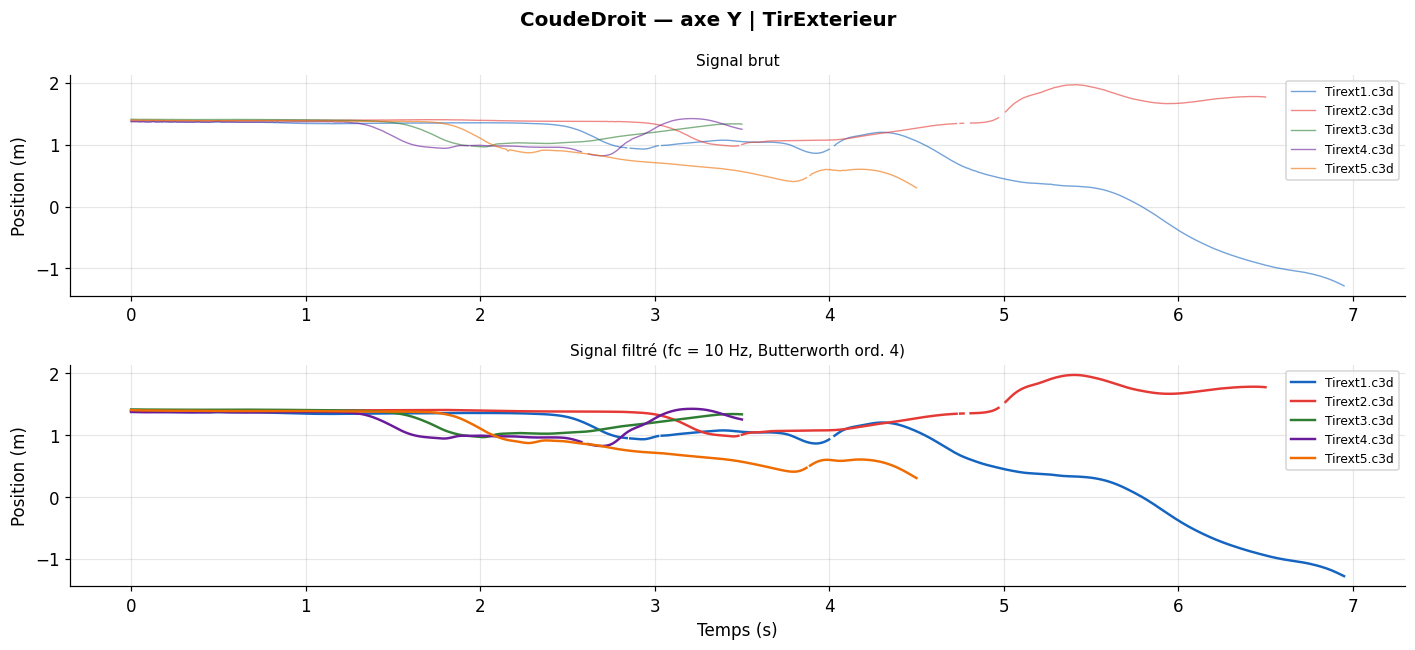

In [11]:
# Superposition du centre du coude droit filtré pour tous les Tirs Extérieurs
condition  = 'TirExterieur'
marqueur   = 'CoudeDroit'
ax_idx     = 1           # axe Y (vertical)
axis_lbl   = 'Y'

colors = ['#1565C0', '#E53935', '#2E7D32', '#6A1B9A', '#EF6C00']

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=False)
fig.suptitle(f'{marqueur} — axe {axis_lbl} | {condition}',
             fontsize=13, fontweight='bold')

for i, (fname, data) in enumerate(resultats[condition].items()):
    freq = data['freq']
    raw  = data['raw'][marqueur][:, ax_idx]
    filt = data['filt'][marqueur][:, ax_idx]
    t = np.arange(len(raw)) / freq
    clr = colors[i % len(colors)]
    axes[0].plot(t, raw,  color=clr, lw=0.9, alpha=0.6, label=fname)
    axes[1].plot(t, filt, color=clr, lw=1.6, label=fname)

axes[0].set_title('Signal brut', fontsize=10)
axes[0].set_ylabel('Position (m)')
axes[1].set_title('Signal filtré (fc = 10 Hz, Butterworth ord. 4)', fontsize=10)
axes[1].set_ylabel('Position (m)')
axes[1].set_xlabel('Temps (s)')

for ax in axes:
    ax.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()

### 5.3 Visualisation des vitesses — effet du filtrage sur la dérivée

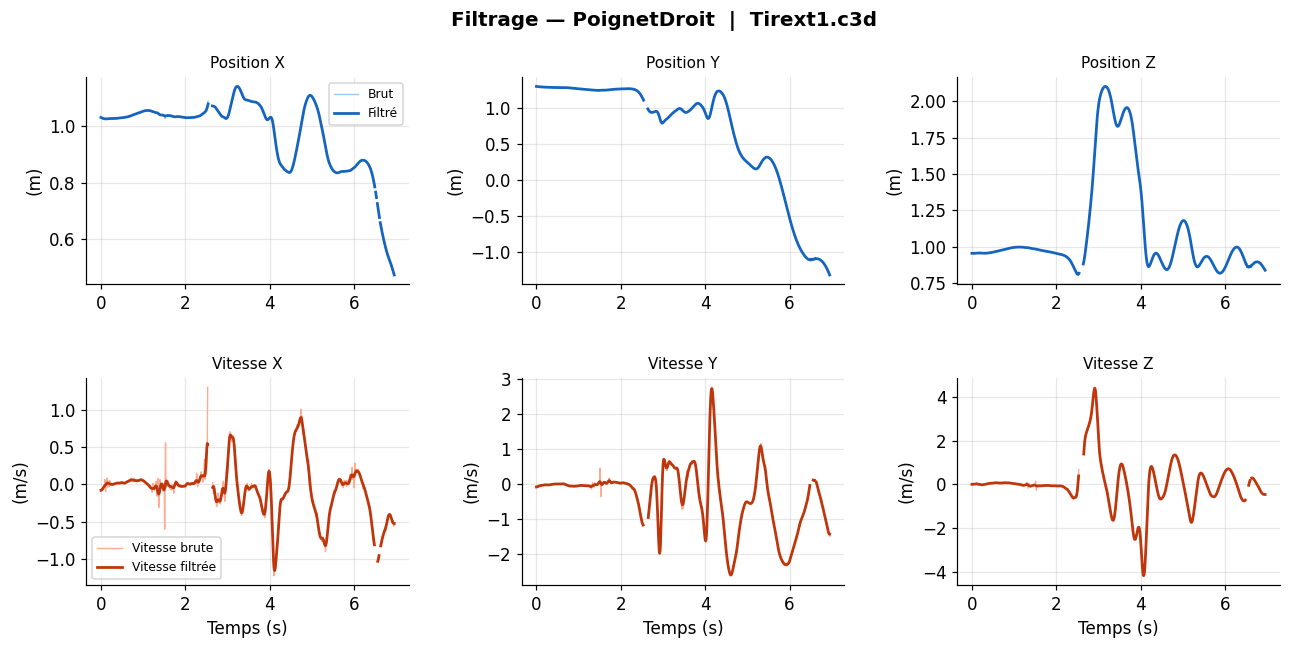

In [12]:
# Comparaison brut vs filtré sur UN essai, pour voir l'effet sur la vitesse
condition_sel = 'TirExterieur'
fichier_sel   = 'Tirext1.c3d'
marqueur_sel  = 'PoignetDroit'

plot_brut_vs_filtre(
    resultats[condition_sel][fichier_sel]['raw'],
    resultats[condition_sel][fichier_sel]['filt'],
    resultats[condition_sel][fichier_sel]['freq'],
    marker_name=marqueur_sel,
    axes_idx=(0, 1, 2),
    titre=f'{fichier_sel}'
)

---
## 6. Accès aux données pour les étapes suivantes

Les données préparées sont stockées dans le dictionnaire `resultats` :

```python
resultats
├── 'LancerFranc'
│   ├── 'Lancer1.c3d'  →  {'raw': dict, 'filt': dict, 'freq': 100.0}
│   ├── 'Lancer2.c3d'  →  ...
│   └── ...
└── 'TirExterieur'
    ├── 'Tirext1.c3d'  →  {'raw': dict, 'filt': dict, 'freq': 100.0}
    └── ...
```

**Chaque valeur `dict`** contient 31 clés : 25 marqueurs bruts + 6 centres articulaires calculés.  
**Chaque tableau** est de shape `(N_frames, 3)` en **mètres**.

In [14]:
# Exemple d'accès
df_tirext1_filt = resultats['TirExterieur']['Tirext1.c3d']['filt']
freq_tirext1    = resultats['TirExterieur']['Tirext1.c3d']['freq']

print("Marqueurs disponibles dans Tirext1 (filtré) :")
for name, arr in df_tirext1_filt.items():
    print(f"  {name:<25}  shape = {arr.shape}")

print(f"\nFréquence : {freq_tirext1} Hz")
print("\n  → Données prêtes pour l'étape 2 (calcul des angles articulaires)")

Marqueurs disponibles dans Tirext1 (filtré) :
  Nuque                      shape = (696, 3)
  EpauleDroitePost           shape = (696, 3)
  EpauleGauchePost           shape = (696, 3)
  EpauleDroiteAnt            shape = (696, 3)
  EpauleGaucheAnt            shape = (696, 3)
  EpauleGaucheLat            shape = (696, 3)
  EpauleDroiteLat            shape = (696, 3)
  CoudeDroitExt              shape = (696, 3)
  CoudeDroitInt              shape = (696, 3)
  HancheDroite               shape = (696, 3)
  HancheGauche               shape = (696, 3)
  CoudeGaucheInt             shape = (696, 3)
  CoudeGaucheExt             shape = (696, 3)
  PoignetDroitExt            shape = (696, 3)
  PoignetDroitInt            shape = (696, 3)
  PoignetGaucheInt           shape = (696, 3)
  PoignetGaucheExt           shape = (696, 3)
  GenouDroitExt              shape = (696, 3)
  MainDroiteDos              shape = (696, 3)
  MainGaucheDos              shape = (696, 3)
  DosDroitBas                shape

---
## 2. Définition et segmentation des phases du tir

Contrairement é une boucle de pédalage qui s'identifie par des pics répétés, un tir correspond é un événement unique. Le mouvement est donc découpé en phases biomécaniques logiques afin de comparer les essais de maniére cohérente.

### événements clés

Les événements sont estimés é partir des trajectoires filtrées des marqueurs :

- **Début du mouvement** : premiére variation significative de la hauteur du centre de masse ;
- **Position minimale** : hauteur minimale du centre de masse, correspondant généralement é la flexion maximale des membres inférieurs ;
- **Libération estimée** : maximum de la vitesse de la main qui tire, utilisé comme approximation du lécher du ballon ;
- **Fin du mouvement** : retour vers une vitesse faible aprés la libération.

La libération est dite *estimée* car le ballon n'est pas suivi par un marqueur. Elle devra étre interprétée avec les angles du coude et du poignet é l'étape suivante.

### Phases retenues

1. **Préparation** : du début du mouvement é la position minimale du centre de masse ;
2. **Propulsion** : de la position minimale é la libération estimée ;
3. **Libération** : instant bref autour de la libération estimée ;
4. **Suivi** : de la libération estimée é la fin du mouvement.

Les essais peuvent ensuite étre normalisés en pourcentage de leur durée pour comparer le lancer franc et le tir extérieur malgré des durées différentes.


In [15]:
# Segmentation automatique d'un essai é partir des marqueurs filtrés
# Les indices retournés correspondent aux frames de l'essai.
def _premier_marqueur_disponible(markers, noms):
    for nom in noms:
        if nom in markers:
            return markers[nom]
    raise KeyError(f"Aucun de ces marqueurs n'est disponible : {noms}")


def segmenter_tir(markers, freq):
    """Estime les événements et les phases d'un tir."""
    n_frames = next(iter(markers.values())).shape[0]

    # Approximation du centre de masse avec les marqueurs du tronc et des hanches.
    noms_com = [
        "HancheDroite", "HancheGauche", "EpauleDroitePost",
        "EpauleGauchePost", "DosDroitBas", "DosGaucheBas",
    ]
    points_com = [markers[nom] for nom in noms_com if nom in markers]
    if not points_com:
        raise KeyError("Marqueurs insuffisants pour calculer le centre de masse.")
    centre_masse = np.nanmean(np.stack(points_com), axis=0)

    # Main droite : elle correspond au membre qui tire dans les essais fournis.
    main = _premier_marqueur_disponible(
        markers, ["MainDroiteDos", "PoignetDroitExt", "PoignetDroitInt"]
    )
    vitesse_main = np.linalg.norm(np.gradient(main, axis=0) * freq, axis=1)
    hauteur_com = centre_masse[:, 2]

    # Début : vitesse de la main supérieure é 10 % de son maximum.
    seuil_vitesse = 0.10 * np.nanmax(vitesse_main)
    candidats_debut = np.flatnonzero(vitesse_main >= seuil_vitesse)
    debut = int(candidats_debut[0]) if len(candidats_debut) else 0

    # Position minimale avant la libération.
    candidats_min = np.arange(debut, n_frames)
    position_min = int(candidats_min[np.nanargmin(hauteur_com[candidats_min])])

    # Libération estimée : vitesse maximale de la main aprés la position minimale.
    liberation = int(position_min + np.nanargmax(vitesse_main[position_min:]))

    # Fin : retour sous le seuil de vitesse aprés la libération.
    candidats_fin = np.flatnonzero(vitesse_main[liberation:] <= seuil_vitesse)
    fin = int(liberation + candidats_fin[0]) if len(candidats_fin) else n_frames - 1
    fin = max(fin, liberation + 1)

    evenements = {
        "debut": debut,
        "position_minimale": position_min,
        "liberation_estimee": liberation,
        "fin": fin,
    }
    phases = {
        "preparation": (debut, position_min),
        "propulsion": (position_min, liberation),
        "liberation": (liberation, min(liberation + 1, fin)),
        "suivi": (liberation, fin),
    }
    return evenements, phases, centre_masse, vitesse_main


evenements_tir, phases_tir, centre_masse_tir, vitesse_main_tir = segmenter_tir(
    markers_ex_filt, freq_ex
)

print("événements détectés (frames) :")
for nom, frame in evenements_tir.items():
    print(f"  {nom:22s}: frame {frame:4d} ({frame / freq_ex:.2f} s)")


événements détectés (frames) :
  debut                 : frame  235 (2.35 s)
  position_minimale     : frame  270 (2.70 s)
  liberation_estimee    : frame  293 (2.93 s)
  fin                   : frame  432 (4.32 s)


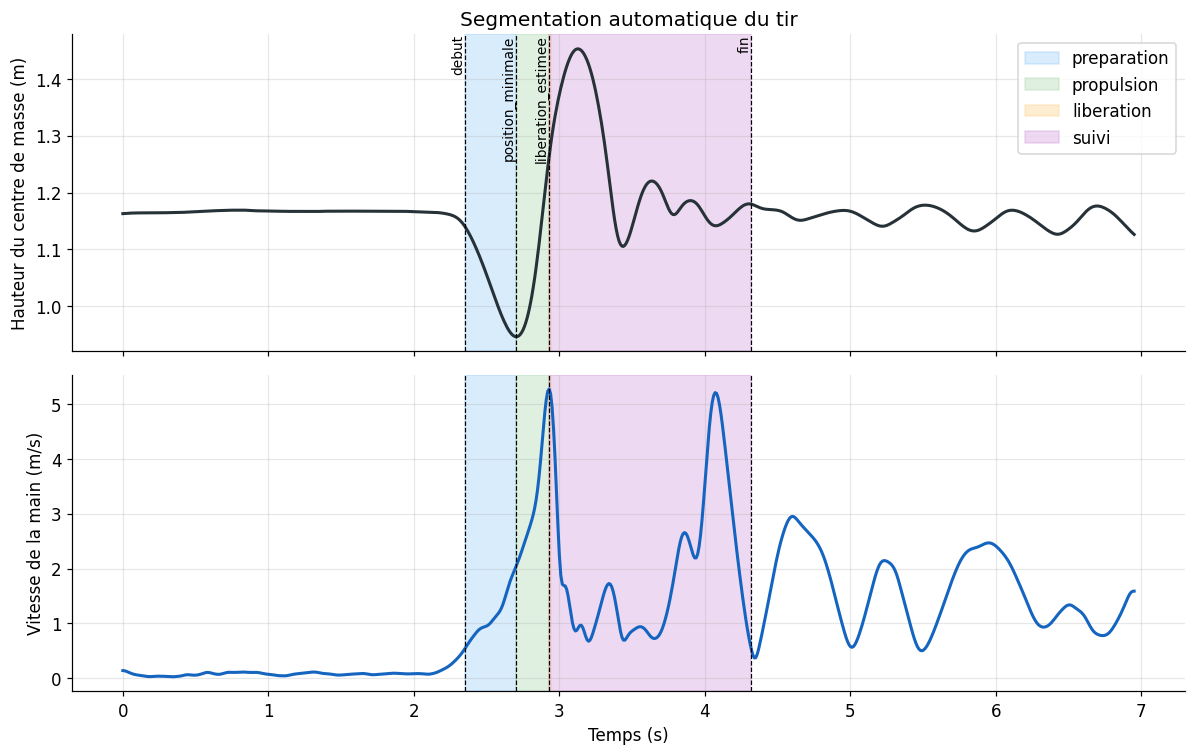

In [16]:
# Visualisation des événements et des phases détectés
frames = np.arange(len(centre_masse_tir))
temps = frames / freq_ex
couleurs_phases = {
    "preparation": "#90CAF9",
    "propulsion": "#A5D6A7",
    "liberation": "#FFCC80",
    "suivi": "#CE93D8",
}

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(temps, centre_masse_tir[:, 2], color="#263238", lw=2)
axes[0].set_ylabel("Hauteur du centre de masse (m)")
axes[0].set_title("Segmentation automatique du tir")
axes[1].plot(temps, vitesse_main_tir, color="#1565C0", lw=2)
axes[1].set_ylabel("Vitesse de la main (m/s)")
axes[1].set_xlabel("Temps (s)")

for nom_phase, (debut, fin) in phases_tir.items():
    for ax in axes:
        ax.axvspan(debut / freq_ex, fin / freq_ex,
                   color=couleurs_phases[nom_phase], alpha=0.35)

for nom, frame in evenements_tir.items():
    for ax in axes:
        ax.axvline(frame / freq_ex, color="black", ls="--", lw=0.8)
    axes[0].text(frame / freq_ex, axes[0].get_ylim()[1], nom,
                 rotation=90, va="top", ha="right", fontsize=9)

axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=couleur, alpha=0.35)
                for couleur in couleurs_phases.values()],
               list(couleurs_phases.keys()), loc="best")
plt.tight_layout()
plt.show()


---
## 3. Calcul des angles articulaires et de l'amplitude (ROM)

Les angles articulaires sont calculés é partir de trois points anatomiques. Pour un angle formé par les vecteurs `A-B` et `C-B`, la méthode utilise la normalisation des vecteurs et le produit scalaire :

$$\theta = \arccos\left(\frac{(A-B) \cdot (C-B)}{\|A-B\|\|C-B\|}\right)$$

Les angles des genoux et des hanches sont étudiés au moment du **Dip**, défini ici par la position minimale du centre de masse. Les angles des coudes et des épaules décrivent la finition du tir. Le ROM correspond é l'amplitude entre la valeur minimale et la valeur maximale d'un angle pendant l'essai.

L'asymétrie est exprimée par la différence absolue entre les ROM droit et gauche, ainsi que par cette différence rapportée au ROM moyen.

> **Limite des données :** aucun marqueur de cheville n'est disponible dans les fichiers fournis. L'angle du genou est donc estimé avec une direction verticale comme référence pour le segment jambier ; il ne s'agit pas d'un angle anatomique complet hanche-genou-cheville.


In [19]:
def angle_3_points(point_a, point_b, point_c):
    """Calcule l'angle A-B-C en degrés, frame par frame."""
    vecteur_ba = np.asarray(point_a, dtype=float) - np.asarray(point_b, dtype=float)
    vecteur_bc = np.asarray(point_c, dtype=float) - np.asarray(point_b, dtype=float)

    norme_ba = np.linalg.norm(vecteur_ba, axis=-1)
    norme_bc = np.linalg.norm(vecteur_bc, axis=-1)
    denominateur = norme_ba * norme_bc

    with np.errstate(divide="ignore", invalid="ignore"):
        produit_normalise = np.sum(vecteur_ba * vecteur_bc, axis=-1) / denominateur
    produit_normalise = np.clip(produit_normalise, -1.0, 1.0)
    angles = np.degrees(np.arccos(produit_normalise))
    angles[denominateur == 0] = np.nan
    return angles


def milieu_marqueurs(markers, nom_a, nom_b):
    """Retourne le milieu de deux marqueurs anatomiques."""
    return (markers[nom_a] + markers[nom_b]) / 2.0


def calculer_angles_articulaires(markers):
    """Calcule les angles articulaires droits et gauches au cours du temps."""
    epaule_droite = milieu_marqueurs(markers, "EpauleDroitePost", "EpauleDroiteAnt")
    epaule_gauche = milieu_marqueurs(markers, "EpauleGauchePost", "EpauleGaucheAnt")
    coude_droit = milieu_marqueurs(markers, "CoudeDroitExt", "CoudeDroitInt")
    coude_gauche = milieu_marqueurs(markers, "CoudeGaucheExt", "CoudeGaucheInt")
    poignet_droit = milieu_marqueurs(markers, "PoignetDroitExt", "PoignetDroitInt")
    poignet_gauche = milieu_marqueurs(markers, "PoignetGaucheExt", "PoignetGaucheInt")
    genou_droit = milieu_marqueurs(markers, "GenouDroitExt", "GenouDroitInt")
    genou_gauche = milieu_marqueurs(markers, "GenouGaucheExt", "GenouGaucheInt")
    hanche_droite = markers["HancheDroite"]
    hanche_gauche = markers["HancheGauche"]

    # Aucun marqueur de cheville n'est fourni : direction verticale = proxy du segment jambier.
    direction_verticale = np.array([0.0, 0.0, -1.0])
    cheville_proxy_droite = genou_droit + direction_verticale
    cheville_proxy_gauche = genou_gauche + direction_verticale

    return {
        "genou_droit": angle_3_points(hanche_droite, genou_droit, cheville_proxy_droite),
        "genou_gauche": angle_3_points(hanche_gauche, genou_gauche, cheville_proxy_gauche),
        "hanche_droite": angle_3_points(epaule_droite, hanche_droite, genou_droit),
        "hanche_gauche": angle_3_points(epaule_gauche, hanche_gauche, genou_gauche),
        "coude_droit": angle_3_points(epaule_droite, coude_droit, poignet_droit),
        "coude_gauche": angle_3_points(epaule_gauche, coude_gauche, poignet_gauche),
        "epaule_droite": angle_3_points(hanche_droite, epaule_droite, coude_droit),
        "epaule_gauche": angle_3_points(hanche_gauche, epaule_gauche, coude_gauche),
    }


angles_tir = calculer_angles_articulaires(markers_ex_filt)
dip_frame = evenements_tir["position_minimale"]

print(f"Angles calculés sur {len(next(iter(angles_tir.values())))} frames.")
print(f"Dip détecté é la frame {dip_frame} ({dip_frame / freq_ex:.2f} s).")
print("Angles au Dip :")
for nom, valeurs in angles_tir.items():
    print(f"  {nom:16s}: {valeurs[dip_frame]:6.1f} degrés")


Angles calculés sur 696 frames.
Dip détecté é la frame 270 (2.70 s).
Angles au Dip :
  genou_droit     :  150.6 degrés
  genou_gauche    :    nan degrés
  hanche_droite   :  121.8 degrés
  hanche_gauche   :    nan degrés
  coude_droit     :   66.4 degrés
  coude_gauche    :   83.2 degrés
  epaule_droite   :   59.9 degrés
  epaule_gauche   :   63.5 degrés


In [21]:
def resumer_rom(angles):
    """Retourne le minimum, le maximum et le ROM de chaque angle."""
    resume = {}
    for nom, valeurs in angles.items():
        resume[nom] = {
            "minimum": float(np.nanmin(valeurs)),
            "maximum": float(np.nanmax(valeurs)),
            "ROM": float(np.nanmax(valeurs) - np.nanmin(valeurs)),
        }
    return resume


def calculer_asymetries(resume):
    """Compare les ROM droit et gauche pour chaque articulation."""
    asymetries = {}
    cles_articulations = {
        "genou": ("genou_droit", "genou_gauche"),
        "hanche": ("hanche_droite", "hanche_gauche"),
        "coude": ("coude_droit", "coude_gauche"),
        "epaule": ("epaule_droite", "epaule_gauche"),
    }
    for articulation, (cle_droite, cle_gauche) in cles_articulations.items():
        rom_droit = resume[cle_droite]["ROM"]
        rom_gauche = resume[cle_gauche]["ROM"]
        rom_moyen = (rom_droit + rom_gauche) / 2.0
        asymetries[articulation] = {
            "ROM_droit": rom_droit,
            "ROM_gauche": rom_gauche,
            "difference_absolue": abs(rom_droit - rom_gauche),
            "asymetrie_pourcent": 100.0 * abs(rom_droit - rom_gauche) / rom_moyen
            if rom_moyen > 0 else np.nan,
        }
    return asymetries


resume_angles = resumer_rom(angles_tir)
asymetries_angles = calculer_asymetries(resume_angles)

print("\nAmplitude articulaire (ROM) :")
for nom, valeurs in resume_angles.items():
    print(f"  {nom:16s}: {valeurs['ROM']:6.1f} degrés")

print("\nAsymétrie des ROM :")
for nom, valeurs in asymetries_angles.items():
    print(f"  {nom:8s}: {valeurs['asymetrie_pourcent']:5.1f} %")



Amplitude articulaire (ROM) :
  genou_droit     :   29.0 degrés
  genou_gauche    :   30.5 degrés
  hanche_droite   :   57.9 degrés
  hanche_gauche   :   49.4 degrés
  coude_droit     :  125.2 degrés
  coude_gauche    :  120.6 degrés
  epaule_droite   :  111.9 degrés
  epaule_gauche   :  111.6 degrés

Asymétrie des ROM :
  genou   :   5.3 %
  hanche  :  15.8 %
  coude   :   3.8 %
  epaule  :   0.2 %


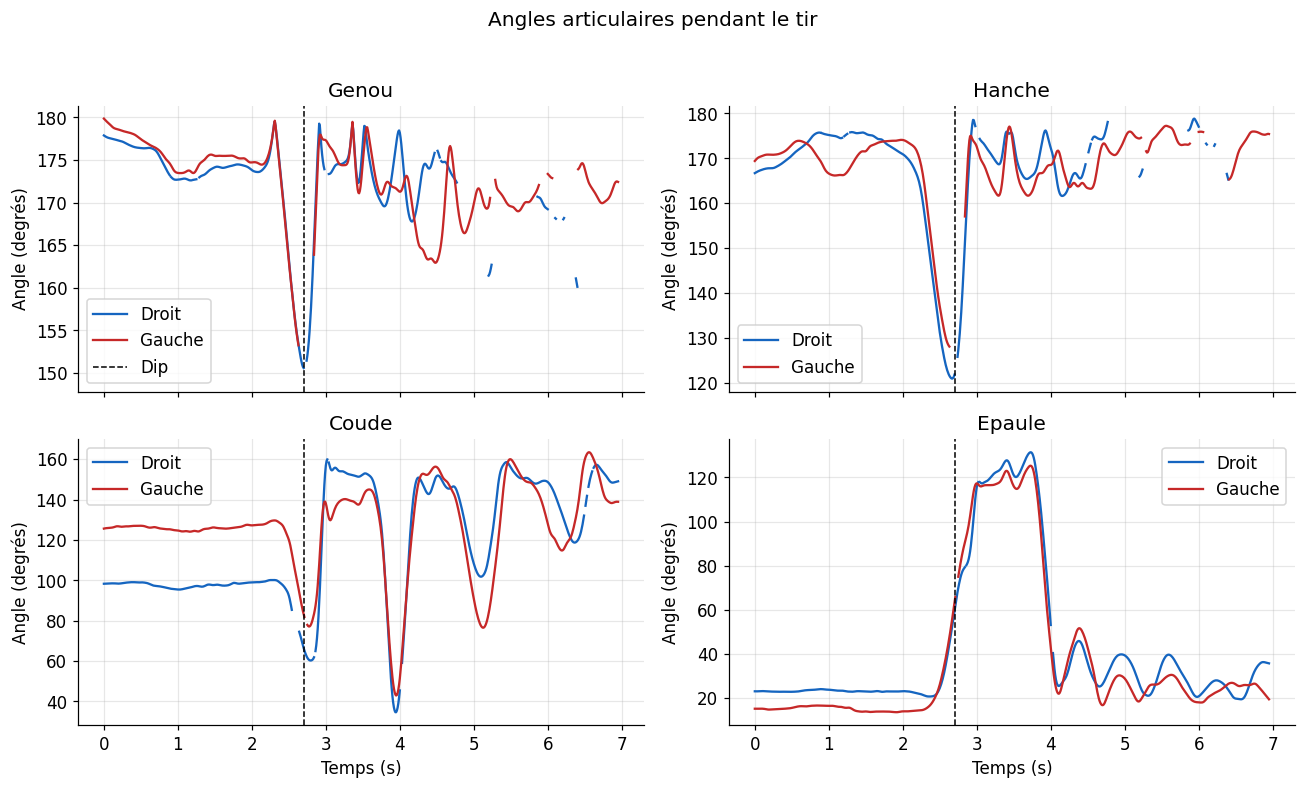

In [23]:
# évolution des angles articulaires au cours du tir
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
cles_angles = {
    "genou": ("genou_droit", "genou_gauche"),
    "hanche": ("hanche_droite", "hanche_gauche"),
    "coude": ("coude_droit", "coude_gauche"),
    "epaule": ("epaule_droite", "epaule_gauche"),
}

for ax, articulation in zip(axes.flat, cles_angles):
    for nom, cote, couleur in [
        (cles_angles[articulation][0], "Droit", "#1565C0"),
        (cles_angles[articulation][1], "Gauche", "#C62828"),
    ]:
        ax.plot(np.arange(len(angles_tir[nom])) / freq_ex,
                angles_tir[nom], color=couleur, label=cote)
    ax.axvline(dip_frame / freq_ex, color="black", ls="--", lw=1,
               label="Dip" if articulation == "genou" else None)
    ax.set_title(articulation.capitalize())
    ax.set_ylabel("Angle (degrés)")
    ax.legend()
axes[-1, 0].set_xlabel("Temps (s)")
axes[-1, 1].set_xlabel("Temps (s)")
fig.suptitle("Angles articulaires pendant le tir", y=1.02)
plt.tight_layout()
plt.show()
